# Regime-Matched PCA Fair Value: SOFR Swap Flies

A plain rolling PCA uses only the last 3 months to define level, slope and curvature. This notebook also builds a **regime-matched** version:

1. Find the 3 past 3-month windows whose market regime (volatility, factor mix, front/back correlation) looks most like today's.
2. Estimate the PCA loadings from those windows instead.
3. Compute both fair values, compare the fly residuals, and check whether either one predicts mean reversion over the next 10 days.

> **No carry, roll, costs or P&L anywhere in this notebook.** The data is **simulated**, so every result here is a plumbing test of the code and says nothing about real edge.

## 1. Config

In [1]:
csv_path       = "sofr_swap_rates_simulated.csv"   # simulated daily levels (stand-in for the work CSV)
tenors         = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 25, 30]
start_date     = "2022-01-01"   # no data before this is used
window         = 63             # 3M window of daily changes (PCA and regime features)
z_window       = 126            # past fly residuals used for the z-score
n_factors      = 3
k_matches      = 3              # number of matched historical windows
refit_every    = 5              # refit loadings and matches every N days (reused in between)
entry_z        = 2.0
horizon        = 10             # days ahead for the reversal check
split_date     = None           # None = midpoint of the usable sample
anchors        = None           # None = fit scores on all tenors; or e.g. [3, 5, 10, 30]
max_wing_ratio = 4              # flies: long <= max_wing_ratio * short
fly_list       = None           # None = all combos; or e.g. [(3, 4, 5), (5, 7, 10), (10, 20, 30)]
seed           = 7              # random day for the no-look-ahead test

In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
C_BLUE, C_ORANGE, C_AQUA, C_INK, C_MUTED, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#b8b7b0"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.titleweight": "bold", "axes.titlesize": 12, "legend.frameon": False,
                     "xtick.color": C_MUTED, "ytick.color": C_MUTED, "axes.labelcolor": C_MUTED})
assert 3 in tenors and 30 in tenors, "the 3y-30y correlation feature needs both tenors"

## 2. Data

`load_curve()` is the only place data is read, so swapping in the work CSV only means editing this function. It:

- parses column labels like `"3y"` into tenor years,
- converts percent to bp when the median |rate| is below 25,
- forward-fills gaps of up to 3 rows and drops any row still incomplete,
- prints what it did.

In [3]:
def load_curve(path=csv_path) -> pd.DataFrame:
    raw = pd.read_csv(path, index_col=0, parse_dates=True)         # <-- swap the reader here for work data
    raw = raw.rename(columns=lambda c: int(float(str(c).lower().rstrip("y"))))
    df = raw[tenors].apply(pd.to_numeric, errors="coerce").sort_index()
    df = df[~df.index.duplicated(keep="last")]
    med = float(np.nanmedian(df.abs().values))
    if med < 25:                                                     # swap rates in % are ~0-10, in bp ~0-1000
        df = df * 100.0
    n_nan = int(df.isna().sum().sum())
    df = df.ffill(limit=3)
    n_bad = int(df.isna().any(axis=1).sum())
    df = df.dropna()
    print(f"load_curve: {'percent -> bp (x100)' if med < 25 else 'already bp'}; {n_nan} missing values, "
          f"ffilled up to 3 rows, {n_bad} incomplete rows dropped; {len(df)} rows "
          f"{df.index[0]:%Y-%m-%d} to {df.index[-1]:%Y-%m-%d}")
    df.index.name, df.columns.name = "date", "tenor"
    return df


curve = load_curve().loc[start_date:]
print(f"Main sample from {start_date}: {len(curve)} rows")

load_curve: percent -> bp (x100); 0 missing values, ffilled up to 3 rows, 0 incomplete rows dropped; 2608 rows 2016-01-04 to 2025-12-31
Main sample from 2022-01-01: 1043 rows


## 3. Method

**No look-ahead.** On day *d*, everything estimated uses data up to *d−1*. Day *d*'s levels are only projected onto the loadings.

- **Plain loadings:** PCA on the covariance (not correlation) of daily bp changes over the 63 days ending *d−1*. The top 3 PCs are kept.
- **Regime features** of a 63-day window of changes:
  - the average |daily move| across tenors (bp/day),
  - the share of variance explained by each of PC1, PC2 and PC3,
  - the correlation between 3y and 30y daily changes.
- **Matching.** The candidates are all past windows that ended **before the current window started**. Each feature is z-standardised across the candidates, the Euclidean distance to today's window is computed, and the `k_matches` closest windows that **don't overlap each other** are kept. The loadings themselves are never used for matching.
- **Matched loadings.** The daily changes of the matched windows are stacked and one PCA is run on the stack. Its PCs are ordered by variance, and any PC is flipped if it points the opposite way to the plain loadings.
- **Fair value** (for both sets of loadings):
  - subtract the mean level over the current window, ending *d−1*;
  - solve least squares of day *d*'s demeaned levels on the loadings (all tenors, or the anchors only) to get 3 scores;
  - residual = actual − fitted, in bp. **Positive = cheap, negative = rich.**
- **Flies.**
  - Fly residual = 2 × belly − short − long, using the residuals.
  - The z-score is measured against the past 126 fly residuals.
  - The raw fly rate is kept for the reversal check.
- **Refits.** Loadings and matches are refit every `refit_every` days. The window mean is updated daily.
- **Fallback.** With fewer than `k_matches` non-overlapping candidate windows, the matched loadings fall back to the plain ones, and the notebook says so.

In [4]:
def pca(changes, k=n_factors):
    # Eigen-decompose the covariance of bp changes; return top-k loadings (columns) and variance shares.
    vals, vecs = np.linalg.eigh(np.cov(changes, rowvar=False))
    order = np.argsort(vals)[::-1]
    return vecs[:, order[:k]], vals[order] / vals.sum()


def window_features(dx, i3, i30):
    # Regime fingerprint of one window: avg |move|, PC1-3 variance shares, corr(3y, 30y).
    _, share = pca(dx)
    return np.r_[np.abs(dx).mean(), share[:3], np.corrcoef(dx[:, i3], dx[:, i30])[0, 1]]


FEATURES = ["avg |move| (bp/d)", "PC1 share", "PC2 share", "PC3 share", "corr 3y-30y"]


def run_pipeline(levels, W=window, k=k_matches):
    X = levels.values
    dX = np.vstack([np.full(X.shape[1], np.nan), np.diff(X, axis=0)])     # dX[i] = X[i] - X[i-1]
    n, m = X.shape
    cols = list(levels.columns)
    i3, i30 = cols.index(3), cols.index(30)
    rows = np.arange(m) if anchors is None else np.array([cols.index(a) for a in anchors])

    # Features of the window of changes ENDING at row e (rows e-W+1..e). Only rows <= e are used.
    feats = np.full((n, len(FEATURES)), np.nan)
    for e in range(W, n):
        feats[e] = window_features(dX[e - W + 1: e + 1], i3, i30)

    res_p, res_m = np.full((n, m), np.nan), np.full((n, m), np.nan)
    fallback = np.zeros(n, bool)
    cos, expl_p, expl_m, picks = {}, {}, {}, {}
    first = W + 1                                     # first day with W changes strictly before it
    for d in range(first, n):
        if (d - first) % refit_every == 0:
            Lp, sp = pca(dX[d - W: d])                # plain: changes on days d-W .. d-1
            cand = np.arange(W, d - W)                # candidate window ends: finished before d-W
            chosen = []
            if len(cand) >= k:
                C = feats[cand]
                sd = C.std(axis=0); sd[sd == 0] = 1
                dist = np.sqrt((((C - feats[d - 1]) / sd) ** 2).sum(axis=1))
                for j in np.argsort(dist):            # closest first, skipping overlaps with already-picked
                    if all(abs(cand[j] - e) >= W for e in chosen):
                        chosen.append(cand[j])
                        if len(chosen) == k:
                            break
                picks[d] = [(e, dist[np.searchsorted(cand, e)]) for e in chosen]
            if len(chosen) == k:
                Lm, sm = pca(np.vstack([dX[e - W + 1: e + 1] for e in chosen]))
                Lm = Lm * np.where((Lm * Lp).sum(axis=0) < 0, -1, 1)   # align signs to plain
                fb = False
            else:
                Lm, sm, fb = Lp, sp, True
            cos[d], expl_p[d], expl_m[d] = np.abs((Lm * Lp).sum(axis=0)), sp[:n_factors], sm[:n_factors]
        fallback[d] = fb
        y = X[d] - X[d - W: d].mean(axis=0)           # day d demeaned by the current window mean (bp)
        for L, out in ((Lp, res_p), (Lm, res_m)):
            s, *_ = np.linalg.lstsq(L[rows], y[rows], rcond=None)
            out[d] = y - L @ s                        # actual - fitted; positive = cheap

    idx = levels.index
    pcs = [f"PC{i+1}" for i in range(n_factors)]
    to_df = lambda dct: pd.DataFrame(dct, index=pcs).T.set_axis(idx[list(dct)], axis=0)
    return dict(res_plain=pd.DataFrame(res_p, idx, cols), res_matched=pd.DataFrame(res_m, idx, cols),
                fallback=pd.Series(fallback, idx), feats=pd.DataFrame(feats, idx, FEATURES),
                cos=to_df(cos), expl_plain=to_df(expl_p), expl_matched=to_df(expl_m),
                picks=picks, L_plain=Lp, L_matched=Lm, last_refit=max(cos))


def build_flies(cols):
    combos = sorted(fly_list) if fly_list else [c for c in itertools.combinations(cols, 3) if c[2] <= max_wing_ratio * c[0]]
    Wf = pd.DataFrame(0.0, index=[f"{s}s{b}s{l}s" for s, b, l in combos], columns=cols)
    for name, (s, b, l) in zip(Wf.index, combos):
        Wf.loc[name, [s, b, l]] = [-1, 2, -1]         # 2*belly - short - long
    return Wf


def zscore(x, zw=z_window):
    # z on day d vs the previous zw values only (shift(1) keeps day d out of its own mean/std)
    r = x.rolling(zw, min_periods=zw)
    return (x - r.mean().shift(1)) / r.std().shift(1)


def signals(levels):
    out = run_pipeline(levels)
    Wf = build_flies(list(levels.columns))
    for tag in ("plain", "matched"):
        out[f"fly_{tag}"] = out[f"res_{tag}"] @ Wf.T
        out[f"z_{tag}"] = zscore(out[f"fly_{tag}"])
    out["fly_rate"] = levels @ Wf.T
    return out


S = signals(curve)
n_flies = S["fly_rate"].shape[1]
usable = S["z_plain"].dropna(how="all").index.intersection(S["z_matched"].dropna(how="all").index)
fb_days = int(S["fallback"].loc[usable].sum())
print(f"Flies tested: {n_flies}" + (" (from fly_list)" if fly_list else f" (all short<belly<long, long <= {max_wing_ratio}x short)"))
print(f"Usable sample (both z-scores available): {len(usable)} days, "
      f"{usable[0]:%Y-%m-%d} to {usable[-1]:%Y-%m-%d}" if len(usable) else "Usable sample: none")
if S["fallback"].iloc[-1] or fb_days:
    print(f"NOTE: matched loadings FELL BACK to plain on {int(S['fallback'].sum())} days "
          f"({fb_days} inside the usable sample): fewer than {k_matches} non-overlapping past windows. "
          + ("This includes the LATEST day." if S["fallback"].iloc[-1] else "The latest day is properly matched."))

Flies tested: 401 (all short<belly<long, long <= 4x short)
Usable sample (both z-scores available): 853 days, 2022-09-26 to 2025-12-31
NOTE: matched loadings FELL BACK to plain on 265 days (139 inside the usable sample): fewer than 3 non-overlapping past windows. The latest day is properly matched.


## 4. Checks: no look-ahead and units

The test picks a random day *d*, deletes every later row and reruns the whole pipeline. Day *d*'s residuals and z-scores must be identical for both methods.

In [5]:
rng = np.random.default_rng(seed)
pos = int(rng.integers(curve.index.get_loc(usable[0]) if len(usable) > 1 else window + 1, len(curve) - 1))
d = curve.index[pos]
T = signals(curve.iloc[: pos + 1])
for key in ("z_plain", "z_matched", "res_plain", "res_matched"):
    assert np.allclose(S[key].loc[d], T[key].loc[d], atol=1e-9, equal_nan=True), f"LOOK-AHEAD in {key}"
print(f"[PASS] truncated at {d:%Y-%m-%d}: residuals and z-scores identical for both methods.")

for tag in ("plain", "matched"):
    r = S[f"res_{tag}"].dropna().values
    ok = 0.05 < r.std() < 25 and abs(r.mean()) < 1
    print(f"[{'PASS' if ok else 'WARN'}] {tag} residuals in bp: mean {r.mean():+.2f}bp, std {r.std():.2f}bp")

[PASS] truncated at 2025-10-27: residuals and z-scores identical for both methods.
[PASS] plain residuals in bp: mean +0.00bp, std 1.64bp
[PASS] matched residuals in bp: mean +0.00bp, std 1.63bp


## 5. Latest day: rich / cheap by fly

The table is sorted by |matched z|. It shows the flies beyond ±2σ on either method, plus any where plain and matched **disagree on the sign**, up to 25 rows.

- **Highlighted rows** are beyond ±2σ.
- **⚠** marks a sign disagreement: the two loading sets tell different stories, so treat the signal with caution.

In [6]:
day = curve.index[-1]
tbl = pd.DataFrame({"plain resid (bp)": S["fly_plain"].loc[day], "plain z": S["z_plain"].loc[day],
                    "matched resid (bp)": S["fly_matched"].loc[day], "matched z": S["z_matched"].loc[day]})
tbl["label"] = np.where(tbl["matched z"] > 0, "cheap", "rich")
tbl["beyond 2σ"] = (tbl[["plain z", "matched z"]].abs() >= entry_z).any(axis=1)
tbl["sign disagree"] = np.sign(tbl["plain z"]) != np.sign(tbl["matched z"])
tbl = tbl.reindex(tbl["matched z"].abs().sort_values(ascending=False).index)

print(f"{day:%Y-%m-%d} | {n_flies} flies | beyond ±{entry_z:g}σ: {int(tbl['beyond 2σ'].sum())} | "
      f"sign disagreements: {int(tbl['sign disagree'].sum())}"
      + (" | matched loadings FELL BACK to plain today" if S["fallback"].iloc[-1] else ""))
show = tbl[tbl["beyond 2σ"] | tbl["sign disagree"]].head(25).copy()
show["sign disagree"] = np.where(show["sign disagree"], "⚠", "")
show["beyond 2σ"] = np.where(show["beyond 2σ"], "✓", "")
hl = lambda row: ["background-color: #fdecc8" if row["beyond 2σ"] else ""] * len(row)
display(show.style.apply(hl, axis=1).format({c: "{:+.2f}" for c in show.columns[:4]}))

2025-12-31 | 401 flies | beyond ±2σ: 44 | sign disagreements: 65


,plain resid (bp),plain z,matched resid (bp),matched z,label,beyond 2σ,sign disagree
5s6s14s,+5.94,+2.50,+5.19,+2.48,cheap,✓,
5s6s15s,+7.19,+3.06,+5.80,+2.34,cheap,✓,
5s6s20s,+7.66,+3.09,+5.57,+2.27,cheap,✓,
3s6s12s,+5.88,+2.44,+5.54,+2.24,cheap,✓,
3s7s11s,+6.74,+2.74,+4.52,+2.21,cheap,✓,
3s7s12s,+6.48,+2.68,+5.23,+2.21,cheap,✓,
3s6s11s,+6.14,+2.25,+4.83,+2.19,cheap,✓,
5s6s11s,+6.41,+2.52,+5.08,+2.15,cheap,✓,
5s7s14s,+6.55,+2.73,+4.88,+2.05,cheap,✓,
5s7s20s,+8.26,+3.35,+5.26,+2.04,cheap,✓,


## 6. Matching diagnostics

These are the historical windows picked at the latest refit, with their regime features next to the current window's. The bar chart shows the **cosine similarity** between each plain PC and its matched counterpart, averaged over time (1 = identical shape).

> If the similarity is above ~0.95 for every PC, matching barely changes the loadings and adds little over the plain PCA. Lower values, usually on PC3, mean the matched regime implies a genuinely different curvature shape.

Matches used for 2025-12-31 (refit on 2025-12-26):


,start,end,distance,avg |move| (bp/d),PC1 share,PC2 share,PC3 share,corr 3y-30y
window,,,,,,,,
current,2025-09-30,2025-12-25,0.00,3.97,91.2%,5.8%,1.4%,0.59
match 1,2023-07-13,2023-10-09,0.56,4.02,91.1%,5.6%,1.7%,0.56
match 2,2023-11-30,2024-02-26,0.84,3.76,90.0%,5.9%,1.9%,0.58
match 3,2024-04-03,2024-06-28,0.87,3.72,89.8%,6.4%,1.4%,0.57


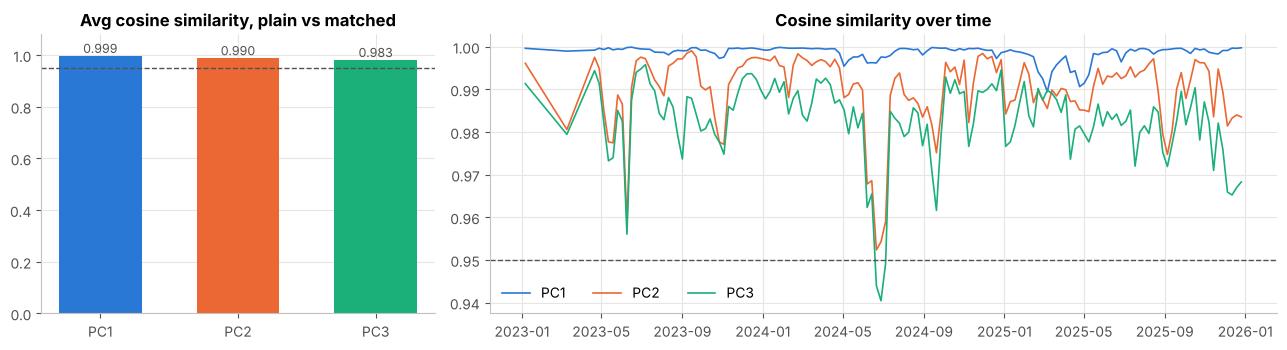

Average cosine similarity: PC1 0.999, PC2 0.990, PC3 0.983 -> matching adds little


In [7]:
ref = S["last_refit"]
if ref in S["picks"] and not S["fallback"].iloc[-1]:
    idx = curve.index
    rows = [("current", idx[ref - window], idx[ref - 1], 0.0, *S["feats"].iloc[ref - 1])]
    rows += [(f"match {i+1}", idx[e - window + 1], idx[e], dist, *S["feats"].iloc[e])
             for i, (e, dist) in enumerate(S["picks"][ref])]
    mt = pd.DataFrame(rows, columns=["window", "start", "end", "distance", *FEATURES]).set_index("window")
    print(f"Matches used for {curve.index[-1]:%Y-%m-%d} (refit on {idx[ref]:%Y-%m-%d}):")
    display(mt.style.format({"start": "{:%Y-%m-%d}", "end": "{:%Y-%m-%d}", "distance": "{:.2f}",
                             FEATURES[0]: "{:.2f}", **{f: "{:.1%}" for f in FEATURES[1:4]}, FEATURES[4]: "{:.2f}"}))
else:
    print("Latest day uses the plain fallback (not enough history for matching): no matches to show.")

cos = S["cos"][~S["fallback"].loc[S["cos"].index]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2]})
a1.bar(cos.columns, cos.mean(), color=[C_BLUE, C_ORANGE, C_AQUA][:n_factors], width=0.6)
a1.axhline(0.95, color=C_MUTED, ls="--", lw=1)
for i, v in enumerate(cos.mean()):
    a1.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9, color=C_MUTED)
a1.set_ylim(0, 1.08); a1.set_title("Avg cosine similarity, plain vs matched")
for c, col in zip(cos.columns, [C_BLUE, C_ORANGE, C_AQUA]):
    a2.plot(cos.index, cos[c], color=col, lw=1.2, label=c)
a2.axhline(0.95, color=C_MUTED, ls="--", lw=1); a2.legend(ncol=3, loc="lower left"); a2.set_title("Cosine similarity over time")
plt.tight_layout(); plt.show()
print("Average cosine similarity:", ", ".join(f"{c} {v:.3f}" for c, v in cos.mean().items()),
      "-> matching adds little" if (cos.mean() > 0.95).all() else "-> matched loadings differ materially on at least one PC")

## 7. PCA sanity

Expect roughly 90% / 6–9% / 1–3% variance from PC1 / PC2 / PC3 on real data, with a flat level, a slope with opposite signs at the ends, and curvature with the belly against the wings. Residuals should be a few bp and centred near zero.

,PC1,PC2,PC3,total
plain,88.4%,7.3%,2.4%,98.1%
matched,88.4%,7.3%,2.5%,98.3%


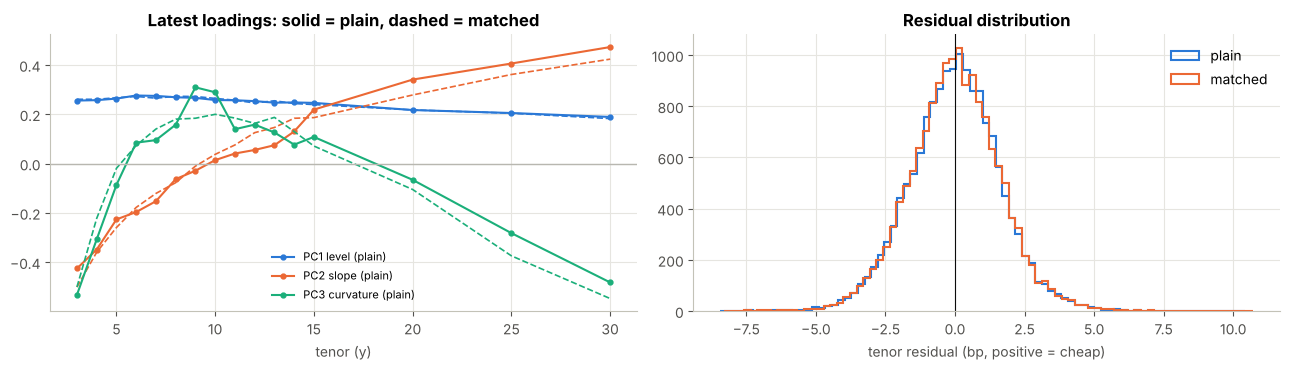

In [8]:
ev = pd.DataFrame({"plain": S["expl_plain"].mean(), "matched": S["expl_matched"].mean()})
ev.loc["total"] = ev.sum()
display(ev.T.style.format("{:.1%}"))

Lp, Lm = S["L_plain"].copy(), S["L_matched"].copy()
flip = np.array([Lp[:, 0].sum() < 0, Lp[-1, 1] < Lp[0, 1], False][:n_factors])  # display orientation only
Lp[:, flip] *= -1; Lm[:, flip] *= -1
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
for j, (col, name) in enumerate(zip([C_BLUE, C_ORANGE, C_AQUA], ["level", "slope", "curvature"])):
    a1.plot(tenors, Lp[:, j], color=col, marker="o", ms=3.5, label=f"PC{j+1} {name} (plain)")
    a1.plot(tenors, Lm[:, j], color=col, ls="--", lw=1.2)
a1.axhline(0, color=C_GREY, lw=1); a1.set_xlabel("tenor (y)")
a1.set_title("Latest loadings: solid = plain, dashed = matched"); a1.legend(fontsize=8)
for tag, col in (("plain", C_BLUE), ("matched", C_ORANGE)):
    a2.hist(S[f"res_{tag}"].dropna().values.ravel(), bins=80, histtype="step", lw=1.5, color=col, label=tag)
a2.axvline(0, color=C_INK, lw=0.8); a2.set_xlabel("tenor residual (bp, positive = cheap)")
a2.set_title("Residual distribution"); a2.legend()
plt.tight_layout(); plt.show()

## 8. Reversal check (no P&L)

For each fly and each method, regress the **next-10-day change in the raw fly rate** on today's fly residual, separately in each half of the usable sample. A **negative slope in both halves** means cheap flies tend to richen and rich flies tend to cheapen, i.e. mean reversion.

- First-half observations whose 10-day horizon crosses the split are dropped, so the two halves don't share data.
- The 10-day changes overlap from one day to the next, so the plain OLS t-stats are overstated (roughly by √10). Read them as rankings, not significance levels.
- The table shows the top 5 flies by first-half |t| for each method.

In [9]:
def ols(x, y):
    # y = a + b*x; returns slope, t-stat, R2, n
    ok = ~(np.isnan(x) | np.isnan(y)); x, y = x[ok], y[ok]
    n = len(x)
    if n < 30:
        return np.nan, np.nan, np.nan, n
    xm, ym = x - x.mean(), y - y.mean()
    b = (xm @ ym) / (xm @ xm)
    e = ym - b * xm
    se = np.sqrt((e @ e) / (n - 2) / (xm @ xm))
    return b, b / se, 1 - (e @ e) / (ym @ ym), n


fwd = S["fly_rate"].shift(-horizon) - S["fly_rate"]                      # next-10-day fly change (bp)
split = pd.Timestamp(split_date) if split_date else usable[len(usable) // 2]
h1 = usable[(usable < split) & (usable.map(lambda t: curve.index.get_loc(t)) + horizon < curve.index.get_loc(split))]
h2 = usable[usable >= split]
print(f"Split at {split:%Y-%m-%d}: first half {len(h1)} days, second half {len(h2)} days, {n_flies} flies x 2 methods tested")

rows = []
for tag in ("plain", "matched"):
    for fly in S["fly_rate"].columns:
        r = {"method": tag, "fly": fly}
        for name, dates in (("H1", h1), ("H2", h2)):
            b, t, r2, n = ols(S[f"fly_{tag}"].loc[dates, fly].values, fwd.loc[dates, fly].values)
            r.update({f"{name} slope": b, f"{name} t": t, f"{name} R2": r2, f"{name} n": n})
        rows.append(r)
rev = pd.DataFrame(rows)
rev["reverts both halves"] = (rev["H1 slope"] < 0) & (rev["H2 slope"] < 0)
rev["t < -2 both"] = (rev["H1 t"] < -2) & (rev["H2 t"] < -2)

top = (rev.assign(abs_t=rev["H1 t"].abs()).sort_values("abs_t", ascending=False)
          .groupby("method").head(5).drop(columns=["abs_t", "t < -2 both"]).set_index(["method", "fly"]).sort_index(level=0, sort_remaining=False))
display(top.style.format({c: "{:+.3f}" for c in top.columns if "slope" in c} | {c: "{:+.1f}" for c in top.columns if c.endswith(" t")}
                         | {c: "{:.3f}" for c in top.columns if "R2" in c} | {c: "{:.0f}" for c in top.columns if c.endswith(" n")}))
summary = rev.groupby("method").agg(flies=("fly", "size"), reverts_both=("reverts both halves", "sum"),
                                    strong_both=("t < -2 both", "sum"))
summary.columns = ["flies tested", "negative slope both halves", "t < -2 both halves"]
display(summary)

Split at 2024-05-14: first half 416 days, second half 427 days, 401 flies x 2 methods tested


,flies tested,negative slope both halves,t < -2 both halves
method,,,
matched,401,400,377
plain,401,399,373


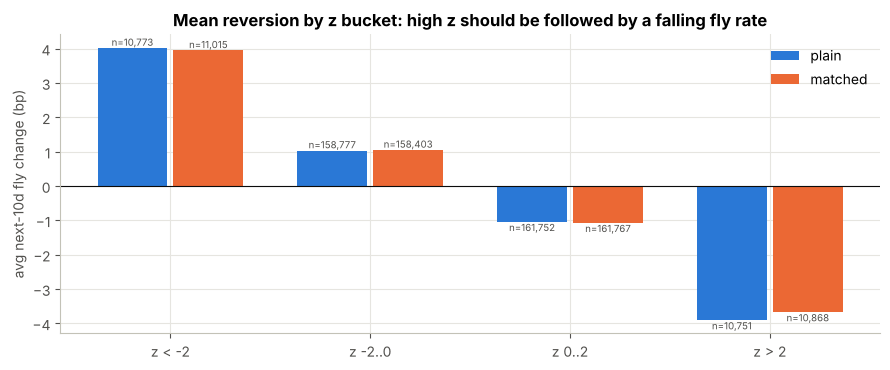

In [10]:
# Average next-10-day fly change by today's z bucket, pooled over all flies and usable days
bins, labels = [-np.inf, -2, 0, 2, np.inf], ["< -2", "-2..0", "0..2", "> 2"]
F = fwd.loc[usable].stack()
bk = {tag: F.groupby(pd.cut(S[f"z_{tag}"].loc[usable].stack(), bins, labels=labels), observed=False).agg(["mean", "size"])
      for tag in ("plain", "matched")}
x = np.arange(4); wdt = 0.38
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (tag, col) in enumerate((("plain", C_BLUE), ("matched", C_ORANGE))):
    ax.bar(x + (i - 0.5) * wdt, bk[tag]["mean"], wdt * 0.92, color=col, label=tag)
    for xi, (m, n) in zip(x, bk[tag].values):
        ax.text(xi + (i - 0.5) * wdt, m, f"n={int(n):,}", ha="center", va="bottom" if m >= 0 else "top", fontsize=7, color=C_MUTED)
ax.axhline(0, color=C_INK, lw=0.8); ax.set_xticks(x); ax.set_xticklabels([f"z {l}" for l in labels])
ax.set_ylabel(f"avg next-{horizon}d fly change (bp)"); ax.legend()
ax.set_title("Mean reversion by z bucket: high z should be followed by a falling fly rate")
plt.tight_layout(); plt.show()

## 9. Read this before using the results

- **No carry, roll, transaction costs or P&L** are included. The reversal check measures moves in the raw fly rate only.
- **The data is simulated.** Every number above tests the code, not the market.
- **Multiple testing.** Many flies are tested with two methods each (the count is printed above), so a few will look good by luck alone. Report the number tested, and trust only results that hold in **both halves** with the same sign.